# Supplementary Figure S10d. Spatial differential expression by AD pathological stage

Gene-level summaries of per-sample spatial transcriptomics DE (Visium; sample-level DE tables), stratified by AD stage (CTRL, AD-Lower, AD-Mid, AD-Higher). Left: *cis*-neuronal genes (neuron-only *cis*-eGenes at loci with glial-only *trans*-eGenes or glial top-10% *trans*-eProgram genes) that are Deep-enriched in the pooled Deep (L4-L6) vs Outer (L1-L3) comparison (minimum sample FDR < 0.05 and median log2FC > 0.05 across all samples; 40 genes); each point is one gene's median Deep-vs-Outer logFC across the samples of a stage. Right: glial *trans*-regulated genes (glial-only *trans*-eGenes union glial top-10% *trans*-eProgram genes) selected in CTRL samples (median WM-vs-rest -log10 P > 10 among CTRL samples with logFC > 0 and FDR < 0.05; 90 genes present in all region x stage combinations); each point is one gene's median -log10 P across the samples of a stage, for white matter (WM one-vs-rest test) and cortical layers (weaker of the Deep and Outer one-vs-rest tests per sample). P values are floored at the smallest positive P; the right y axis is pseudo-log. Genes were selected using pooled samples (left) or CTRL samples (right) and then compared across stages, so the selection step is not independent of the displayed values; no statistical test across stages was performed and no error bars or significance marks are drawn. Boxes show median and IQR, whiskers 1.5 IQR.

Input: `data/Figure_S10d_spatial_AD_stage.rds`

In [1]:
library(ggplot2)
library(scales)
library(patchwork)
res <- readRDS("data/Figure_S10d_spatial_AD_stage.rds")
head(res$cis_neuron)
head(res$trans_glia)

,symbol,severe_cate,deep_outer_logFC,n_samples
,<chr>,<fct>,<dbl>,<int>
1,ADD1,CTRL,0.11392337,4
2,ADD1,AD-Lower,0.05883173,10
3,ADD1,AD-Mid,0.11897215,9
4,ADD1,AD-Higher,0.11735923,9
5,ANKH,CTRL,0.09478148,4
6,ANKH,AD-Lower,0.05528605,10


,gene,symbol,severe_cate,neglog10p,n_samples,region
,<chr>,<chr>,<fct>,<dbl>,<int>,<fct>
1,ENSG00000181409,AATK,AD-Lower,26.897603,10,White matter
2,ENSG00000181409,AATK,AD-Mid,3.562184,9,White matter
3,ENSG00000181409,AATK,AD-Higher,3.758668,9,White matter
4,ENSG00000181409,AATK,CTRL,9.664384,4,White matter
5,ENSG00000181409,AATK,AD-Lower,3.857390,10,Cortical layers
6,ENSG00000181409,AATK,AD-Mid,3.468644,9,Cortical layers


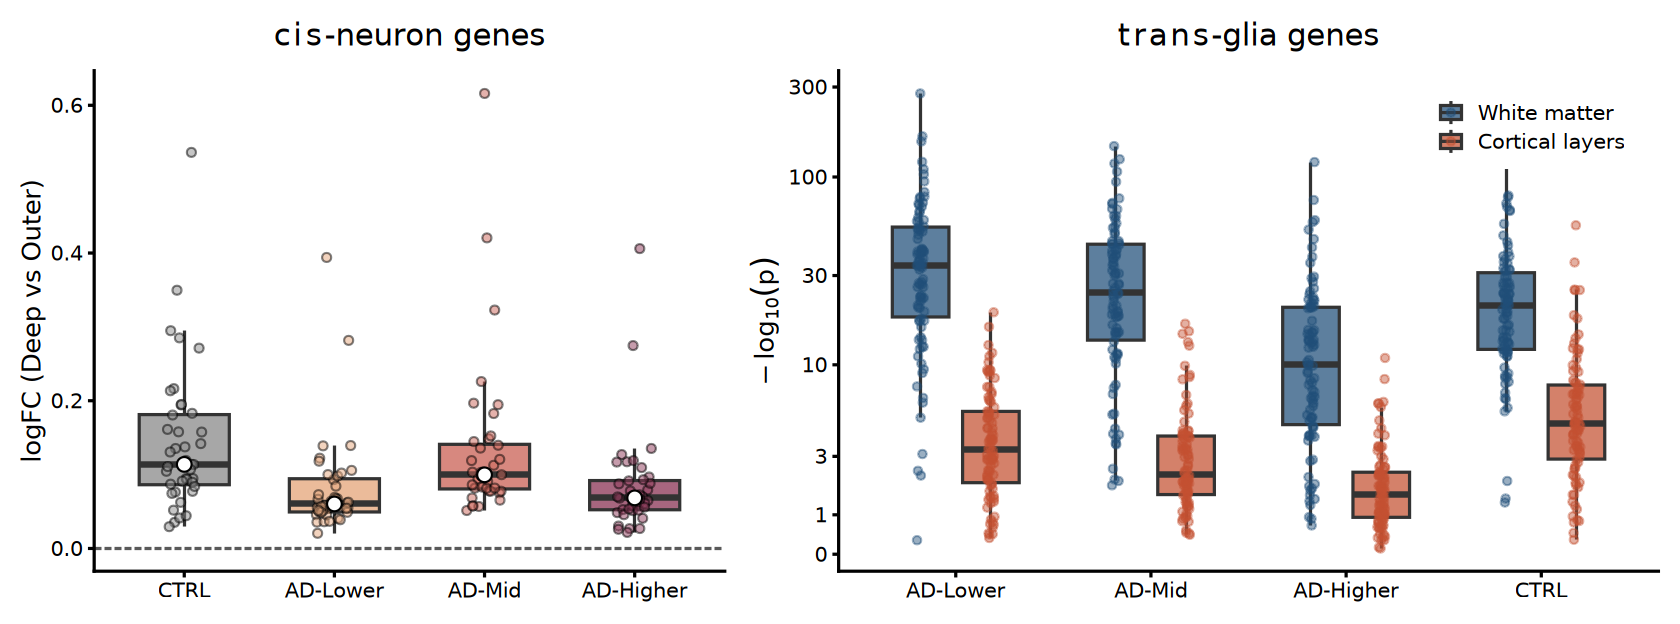

In [2]:
sev_cols <- c("CTRL" = "#8E8E8E", "AD-Lower" = "#E5A87E", "AD-Mid" = "#CB675B", "AD-Higher" = "#8E3B5B")
p_cis <- ggplot(res$cis_neuron, aes(x = severe_cate, y = deep_outer_logFC, fill = severe_cate)) +
  geom_hline(yintercept = 0, linetype = "longdash", colour = "grey35") +
  geom_boxplot(width = 0.6, alpha = 0.78, outlier.shape = NA) +
  geom_point(position = position_jitter(width = 0.12, height = 0, seed = 2026),
             shape = 21, size = 1.8, alpha = 0.5) +
  stat_summary(fun = median, geom = "point", shape = 21, size = 3.4, fill = "white") +
  scale_fill_manual(values = sev_cols, guide = "none") +
  labs(x = NULL, y = "logFC (Deep vs Outer)", title = expression(italic(cis) * "-neuron genes")) +
  theme_classic(base_size = 15) + theme(plot.title = element_text(hjust = 0.5))

reg_cols <- c("White matter" = "#1F4E79", "Cortical layers" = "#C45131")
p_glia <- ggplot(res$trans_glia, aes(x = severe_cate, y = neglog10p, fill = region)) +
  geom_boxplot(position = position_dodge(width = 0.72), width = 0.58, alpha = 0.72,
               outlier.shape = NA) +
  geom_point(aes(colour = region),
             position = position_jitterdodge(jitter.width = 0.08, jitter.height = 0,
                                             dodge.width = 0.72, seed = 2026),
             shape = 21, size = 1.6, alpha = 0.45) +
  scale_fill_manual(values = reg_cols, name = NULL) +
  scale_colour_manual(values = reg_cols, name = NULL) +
  scale_y_continuous(transform = pseudo_log_trans(sigma = 1, base = 10),
                     breaks = c(0, 1, 3, 10, 30, 100, 300)) +
  labs(x = NULL, y = expression(-log[10](p)), title = expression(italic(trans) * "-glia genes")) +
  theme_classic(base_size = 15) +
  theme(plot.title = element_text(hjust = 0.5), legend.position = "inside",
        legend.position.inside = c(0.97, 0.97), legend.justification = c(1, 1))

options(repr.plot.width = 14, repr.plot.height = 5.2)
p_cis + p_glia + plot_layout(widths = c(1, 1.3))